# Proyecto Completo de Machine Learning: Predicción del Gasto Turístico de los Residentes en España (INE - ETR)

* **Autor:** Samuel Márquez Ruiz
* **Módulo:** Curso de Especialización en Inteligencia Artificial y Big Data
* **Vídeo explicativo (YouTube, < 10 min)**: https://youtu.be/2X0sjtpvYqg

## 1. Obtención de datos

Los datos proceden de los **ficheros de microdatos de viajes de la Encuesta de Turismo de Residentes (ETR / Familitur)** publicados por el **Instituto Nacional de Estadística (INE)**, junto con su diseño de registro oficial ([`disreg_etr15csv.xlsx`](https://docs.google.com/spreadsheets/d/1AsXF-zk_wQio3qbsw7yRUnhDyk0zCdw1/edit?usp=sharing&ouid=108079586141267434768&rtpof=true&sd=true)).

* **Medio de obtención:** Encuesta continua realizada por el INE mediante entrevistas telefónicas asistidas por ordenador (CATI) y cuestionarios web (CAWI) a una muestra representativa de hogares residentes en España, recogiendo información detallada sobre los viajes con pernoctación realizados cada mes.
* **Ficheros empleados:**
  * ([`FU_A2025MM11V.csv`](https://drive.google.com/file/d/1berwQ7Qy6nOrgENodDsKr2aASktlOFyB/view?usp=drive_link): viajes realizados en **noviembre de 2025** (3.541 registros).
  * ([`FU_A2025MM12V.csv`](https://drive.google.com/file/d/14XJjUaJL-yIBEMTeIJWMciydDYjLsBXW/view?usp=drive_link): viajes realizados en **diciembre de 2025** (4.044 registros).

Ambos ficheros utilizan punto y coma (`;`) como separador de columnas, coma (`,`) como separador decimal y codificación `latin1`. Los cargamos y concatenamos en un único `DataFrame` de Pandas con **7.585 registros y 117 columnas**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración visual general
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Carga directa de los ficheros CSV (si los tienes en Google Drive, indica la ruta de tu carpeta)
url_nov = "https://drive.google.com/uc?export=download&id=1berwQ7Qy6nOrgENodDsKr2aASktlOFyB"
url_dic = "https://drive.google.com/uc?export=download&id=14XJjUaJL-yIBEMTeIJWMciydDYjLsBXW"
df_nov = pd.read_csv(url_nov, sep=";", decimal=",", encoding="latin1", low_memory=False)
df_dic = pd.read_csv(url_dic, sep=";", decimal=",", encoding="latin1", low_memory=False)

# Unión de ambos meses en un único DataFrame
viajes = pd.concat([df_nov, df_dic], ignore_index=True)

print(f"Registros noviembre 2025: {df_nov.shape[0]}")
print(f"Registros diciembre 2025: {df_dic.shape[0]}")
print(f"Dataset combinado: {viajes.shape[0]} filas y {viajes.shape[1]} columnas")
viajes.head()

Registros noviembre 2025: 3541
Registros diciembre 2025: 4044
Dataset combinado: 7585 filas y 117 columnas


,MES,ANYO,IDSEC,ORDEN_VIAJE,ORDEN_REP,CCAADEST,PROVDEST,PAISDEST,DESTESP,MOTIV,...,RELAECON,SITPROF,TIPHOGAR,MH,VIVSEC,INGR_HOG,CORR15_VT,FACTORVI_15MAS,FACTORVI_TOT,FACTORGAS_TOT
0,11,2025,3878,1,1,16,48,108,1,12,...,3.0,NaN,1,1,1,4,1.0,1540.177240,1540.177240,1540.177240
1,11,2025,13193,1,1,6,39,108,1,7,...,1.0,3.0,4,4,6,5,1.0,5646.617029,5646.617029,5646.617029
2,11,2025,9860,1,1,11,10,108,1,7,...,1.0,3.0,4,4,1,4,1.0,4241.728183,4241.728183,4241.728183
3,11,2025,9860,1,2,11,10,108,1,7,...,1.0,3.0,4,4,1,4,1.0,4241.728183,4241.728183,4241.728183
4,11,2025,3093,2,1,10,3,108,1,8,...,1.0,3.0,3,2,6,3,1.0,2497.263461,2497.263461,2497.263461


## 2. Descripción de los datos

Según el diccionario oficial (`disreg_etr15csv.xlsx`), cada fila representa un viaje con pernoctación realizado por una persona residente en España. Las 117 variables originales se agrupan en cinco bloques:

1. **Identificación y ámbito temporal:**
   * `MES` (`11` o `12`) y `ANYO` (`2025`).
   * `IDSEC`: identificador secuencial de la persona en el mes.
   * `ORDEN_VIAJE` y `ORDEN_REP`: identifican los viajes de la persona y las repeticiones de viajes recurrentes (`ORDEN_REP > 1` cuando el viaje es una repetición).
2. **Características del viaje:**
   * `DESTESP`: destino en España (`1`: Sí, `6`: No / Extranjero).
   * `PAISDEST`: país de destino agregado (`108`: España, `1`: Resto de Europa, `2`: África, `3`: América, `4`: Resto del mundo).
   * `CCAADEST` y `PROVDEST`: comunidad autónoma (`1` a `19`) y provincia de destino (`1` a `52`; `0` cuando el destino es extranjero).
   * `MOTIV`: motivo principal del viaje (`1` a `7`: ocio y vacaciones, `8`: visitas a familiares o amigos, `9` a `15`: compras, estudios, salud, religión u otros personales, `16` a `18`: negocios y motivos profesionales).
   * `TIPOVIAJ`: tipo de viaje (`1`: puente, `2`: fin de semana, `3` a `6`: trabajo o estudio, `7` a `9`: vacaciones de verano/Navidad/Semana Santa, `10`: otros).
   * `NPERNOC` y `NPERNOC_CORR`: número de pernoctaciones original y corregido de valores atípicos.
   * `ALOJAPRIN`: tipo de alojamiento principal (`1` a `9`: alojamientos de mercado como hotel, pensión, vivienda en alquiler, turismo rural, albergue, camping o crucero; `10` a `14`: alojamientos no de mercado como vivienda en propiedad o de familiares/amigos).
   * `TRANSPRIN`: medio de transporte principal (`1`: avión, `2` a `4`: marítimo/crucero/ferry, `5` a `8`: automóvil/taxi, `9`: autobús, `10`: tren, `11` a `12`: no motorizado/otros).
   * `PAQUETE`: contratación de paquete turístico (`1`: Sí, `6`: No, `8`: No sabe).
   * `BLOQUE_ETAPAS`: indica si el viaje tiene varias etapas (`1`: Sí, `6`: No).
3. **Composición del grupo viajero:**
   * Indicadores binarios (`0`: No, `1`: Sí): `VIAJA_SOLO`, `VIAJA_PAREJA`, `VIAJA_HIJOS`, `VIAJA_OTROSFAMILIARES`, `VIAJA_AMIGOS` y `VIAJA_COMPTRABAJO`.
   * Miembros del hogar en el viaje: `MIEMV` (total), `MIEMV_15MAS` (de 15 o más años) y `MIEMV_15MENOS` (menores de 15 años).
4. **Perfil sociodemográfico del viajero:**
   * `SEXO` (`1`: Hombre, `2`: Mujer) y `EDAD` (`15` a `85` años).
   * `CCAA_RESIDENCIA`, `TAMAMU` (tamaño de municipio, `1` a `5`) y `URBA` (grado de urbanización, `1` a `3`).
   * `NIVELEST` (nivel de estudios, `1` a `4`), `RELAECON` (situación laboral, `1` a `4`), `TIPHOGAR` (tipo de hogar, `1` a `5`), `MH` (miembros del hogar), `VIVSEC` (disponibilidad de vivienda secundaria, `1`: Sí, `6`: No) e `INGR_HOG` (tramo de ingresos mensuales del hogar: `1` a `6` de menor a mayor renta, y `9`: No contesta).
5. **Variable objetivo y columnas excluidas para evitar fuga de datos (*data leakage*):**
   * `GASTOFI_TOTAL`: **importe total del gasto del viaje en euros** (variable objetivo o *target*).
   * Se excluyen como predictores los desgloses e indicadores de gasto (`GASTOFI_*`, `GASTO_*`, `IGASTOFI_*`), los factores muestrales (`FACTORVI_15MAS`, `FACTORVI_TOT`, `FACTORGAS_TOT`, `CORR15_VT`), el identificador `IDSEC` y las valoraciones posteriores al viaje (`GRADO_SATISF`, `FIDELIDAD_DEST`).

## 3. Exploración y visualización de los datos

Revisamos primero la presencia de valores nulos, la proporción de viajes repetidos (`ORDEN_REP > 1`) y las estadísticas descriptivas de las variables numéricas principales.

In [ ]:
# Selección de variables candidatas relevantes para el análisis exploratorio
columnas_estudio = [
    "MES", "ORDEN_REP", "DESTESP", "PAISDEST", "CCAADEST", "MOTIV", "TIPOVIAJ",
    "NPERNOC_CORR", "ALOJAPRIN", "TRANSPRIN", "PAQUETE", "BLOQUE_ETAPAS",
    "VIAJA_SOLO", "VIAJA_PAREJA", "VIAJA_HIJOS", "VIAJA_OTROSFAMILIARES",
    "VIAJA_AMIGOS", "VIAJA_COMPTRABAJO", "MIEMV", "MIEMV_15MAS", "MIEMV_15MENOS",
    "SEXO", "EDAD", "CCAA_RESIDENCIA", "TAMAMU", "URBA",
    "NIVELEST", "RELAECON", "TIPHOGAR", "MH", "VIVSEC", "INGR_HOG",
    "GASTOFI_TOTAL"
]

df_eda = viajes[columnas_estudio].copy()

# Revisión de valores nulos
nulos = df_eda.isnull().sum()
print("Variables con valores nulos:")
print(nulos[nulos > 0])

# Comprobación de viajes únicos vs. repeticiones recurrentes
print(f"\nViajes únicos (ORDEN_REP == 1): {(df_eda['ORDEN_REP'] == 1).sum()}")
print(f"Repeticiones (ORDEN_REP > 1):    {(df_eda['ORDEN_REP'] > 1).sum()}")

# Estadísticas descriptivas de variables numéricas continuas o de conteo
df_eda[["NPERNOC_CORR", "MIEMV", "EDAD", "MH", "GASTOFI_TOTAL"]].describe().round(2)

Variables con valores nulos:
PAQUETE                  347
VIAJA_SOLO               347
VIAJA_PAREJA             347
VIAJA_HIJOS              347
VIAJA_OTROSFAMILIARES    347
VIAJA_AMIGOS             347
VIAJA_COMPTRABAJO        347
NIVELEST                  16
RELAECON                  16
dtype: int64

Viajes únicos (ORDEN_REP == 1): 5895
Repeticiones (ORDEN_REP > 1):    1690


,NPERNOC_CORR,MIEMV,EDAD,MH,GASTOFI_TOTAL
count,7585.00,7585.00,7585.00,7585.00,7585.00
mean,3.49,1.87,49.94,2.56,365.90
std,4.39,1.05,15.79,1.24,548.70
min,1.00,1.00,15.00,1.00,19.72
25%,2.00,1.00,39.00,2.00,99.78
50%,2.00,2.00,50.00,2.00,208.70
75%,4.00,2.00,62.00,3.00,414.19
max,69.00,7.00,85.00,10.00,15090.44


### Observaciones iniciales sobre los nulos, duplicados y distribuciones

* **Cero nulos en el target (`GASTOFI_TOTAL`):** Todos los registros incluyen el gasto total (mínimo 19,72 €, mediana 208,70 €, media 365,90 € y máximo 15.090,44 €).
* **Nulos estructurales por el flujo del cuestionario:**
  * Las 6 variables de acompañantes (`VIAJA_*`) y `PAQUETE` presentan **347 nulos (4,6%)**. Según el diseño del cuestionario, estas preguntas no se realizan en desplazamientos habituales al centro de trabajo o estudios; en nuestros datos de noviembre y diciembre, todos esos 347 casos corresponden a `MOTIV = 17` (desplazamiento al centro de trabajo).
  * `NIVELEST` y `RELAECON` tienen **16 nulos (0,2%)**, que corresponden únicamente a viajeros de 15 años (el INE recoge estas dos variables a partir de los 16 años).
* **Viajes recurrentes repetidos:** Hay **1.690 filas con `ORDEN_REP > 1`** que repiten el mismo viaje y prácticamente siempre el mismo gasto total. Si no se filtran antes de entrenar, un mismo viaje podría aparecer a la vez en entrenamiento y en prueba.
* **Asimetría positiva:** Tanto `GASTOFI_TOTAL` como `NPERNOC_CORR` presentan una cola larga a la derecha por los viajes largos e internacionales.

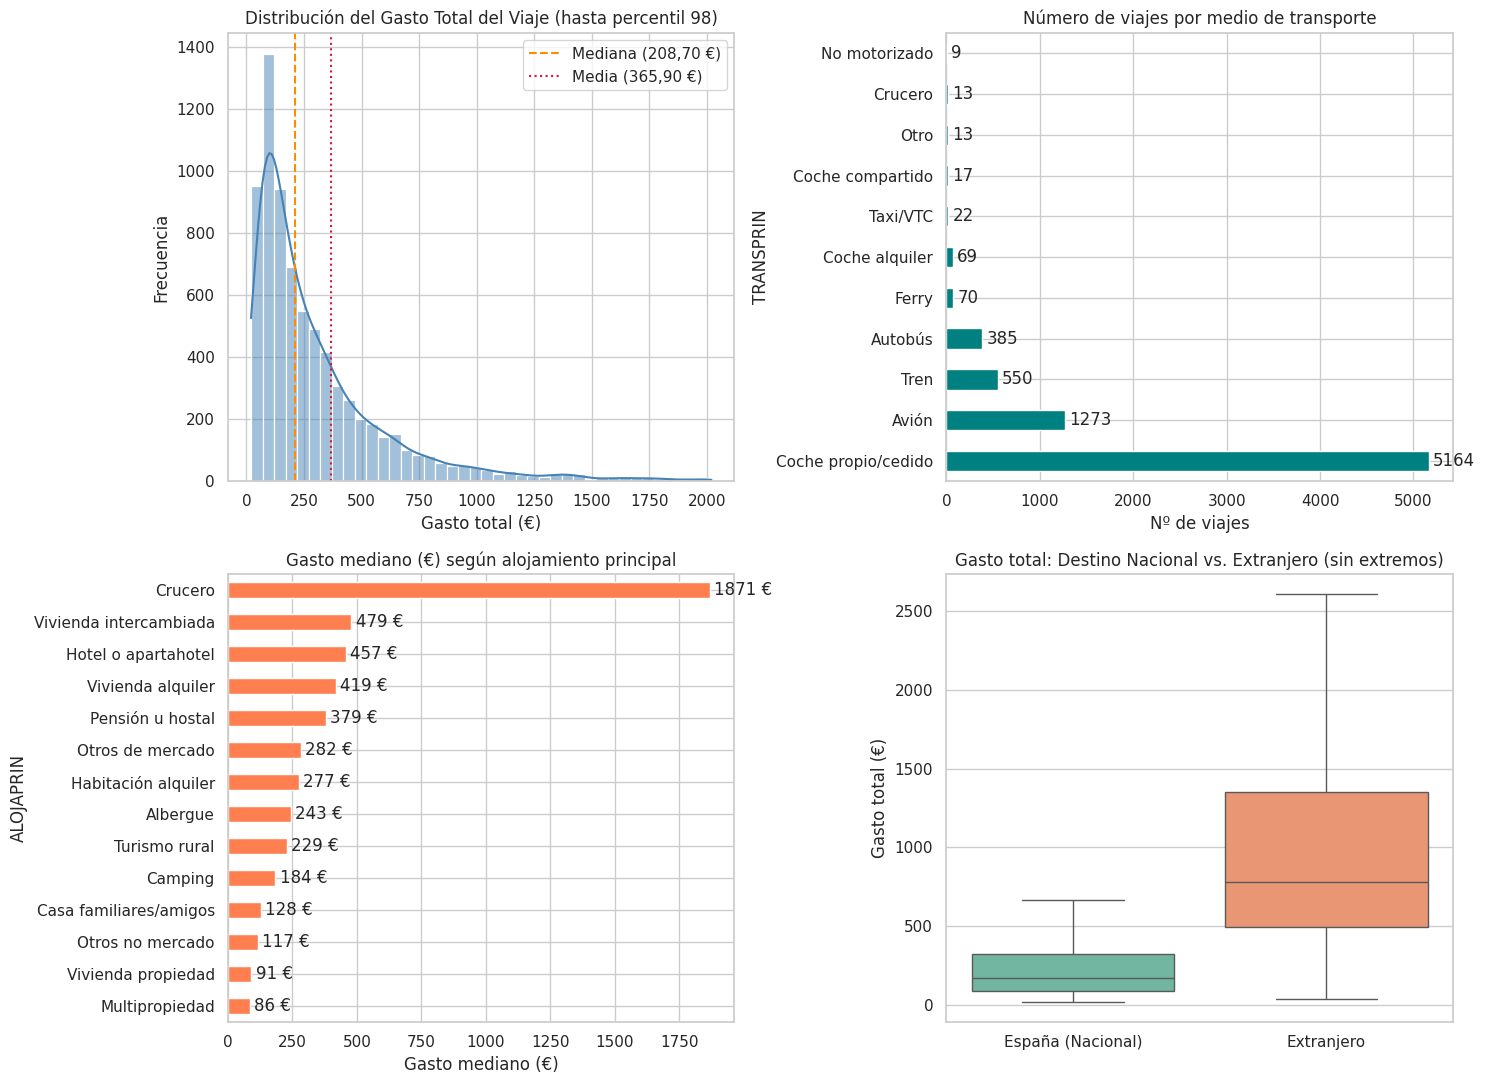

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Histograma del gasto total (recortado al percentil 98 para ver mejor la distribución)
p98 = df_eda["GASTOFI_TOTAL"].quantile(0.98)
gasto_recortado = df_eda[df_eda["GASTOFI_TOTAL"] <= p98]["GASTOFI_TOTAL"]
sns.histplot(gasto_recortado, bins=40, kde=True, ax=axes[0, 0], color="steelblue")
axes[0, 0].axvline(df_eda["GASTOFI_TOTAL"].median(), color="darkorange", linestyle="--", label="Mediana (208,70 €)")
axes[0, 0].axvline(df_eda["GASTOFI_TOTAL"].mean(), color="crimson", linestyle=":", label="Media (365,90 €)")
axes[0, 0].set_title("Distribución del Gasto Total del Viaje (hasta percentil 98)")
axes[0, 0].set_xlabel("Gasto total (€)")
axes[0, 0].set_ylabel("Frecuencia")
axes[0, 0].legend()

# 2. Número de viajes por medio de transporte principal
mapa_trans = {
    1: "Avión", 2: "Crucero", 3: "Ferry", 5: "Coche propio/cedido",
    6: "Coche alquiler", 7: "Taxi/VTC", 8: "Coche compartido",
    9: "Autobús", 10: "Tren", 11: "No motorizado", 12: "Otro"
}
conteo_trans = df_eda["TRANSPRIN"].map(mapa_trans).value_counts()
ax_t = conteo_trans.plot(kind="barh", ax=axes[0, 1], color="teal")
axes[0, 1].set_title("Número de viajes por medio de transporte")
axes[0, 1].set_xlabel("Nº de viajes")
ax_t.bar_label(ax_t.containers[0], padding=3)

# 3. Gasto mediano según tipo de alojamiento principal
mapa_aloja = {
    1: "Hotel o apartahotel", 2: "Pensión u hostal", 3: "Vivienda alquiler",
    4: "Habitación alquiler", 5: "Turismo rural", 6: "Albergue",
    7: "Camping", 8: "Crucero", 9: "Otros de mercado",
    10: "Vivienda propiedad", 11: "Casa familiares/amigos",
    12: "Multipropiedad", 13: "Vivienda intercambiada", 14: "Otros no mercado"
}
gasto_aloja = df_eda.groupby(df_eda["ALOJAPRIN"].map(mapa_aloja))["GASTOFI_TOTAL"].median().sort_values()
ax_a = gasto_aloja.plot(kind="barh", ax=axes[1, 0], color="coral")
axes[1, 0].set_title("Gasto mediano (€) según alojamiento principal")
axes[1, 0].set_xlabel("Gasto mediano (€)")
ax_a.bar_label(ax_a.containers[0], fmt="%.0f €", padding=3)

# 4. Boxplot de gasto total: Destino Nacional vs Extranjero
df_eda["Destino_Tipo"] = df_eda["DESTESP"].map({1: "España (Nacional)", 6: "Extranjero"})
sns.boxplot(
    data=df_eda, x="Destino_Tipo", y="GASTOFI_TOTAL",
    hue="Destino_Tipo", legend=False, showfliers=False,
    ax=axes[1, 1], palette="Set2"
)
axes[1, 1].set_title("Gasto total: Destino Nacional vs. Extranjero (sin extremos)")
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Gasto total (€)")

plt.tight_layout()
plt.show()

Correlación de cada variable con GASTOFI_TOTAL:
GASTOFI_TOTAL          1.000
NPERNOC_CORR           0.577
ES_EXTRANJERO          0.553
TRANSPORTE_AEREO       0.548
ALOJAMIENTO_MERCADO    0.393
USA_PAQUETE            0.282
TIENE_ETAPAS           0.205
VIAJA_SOLO            -0.011
EDAD                  -0.012
MH                    -0.065
MIEMV                 -0.122
Name: GASTOFI_TOTAL, dtype: float64


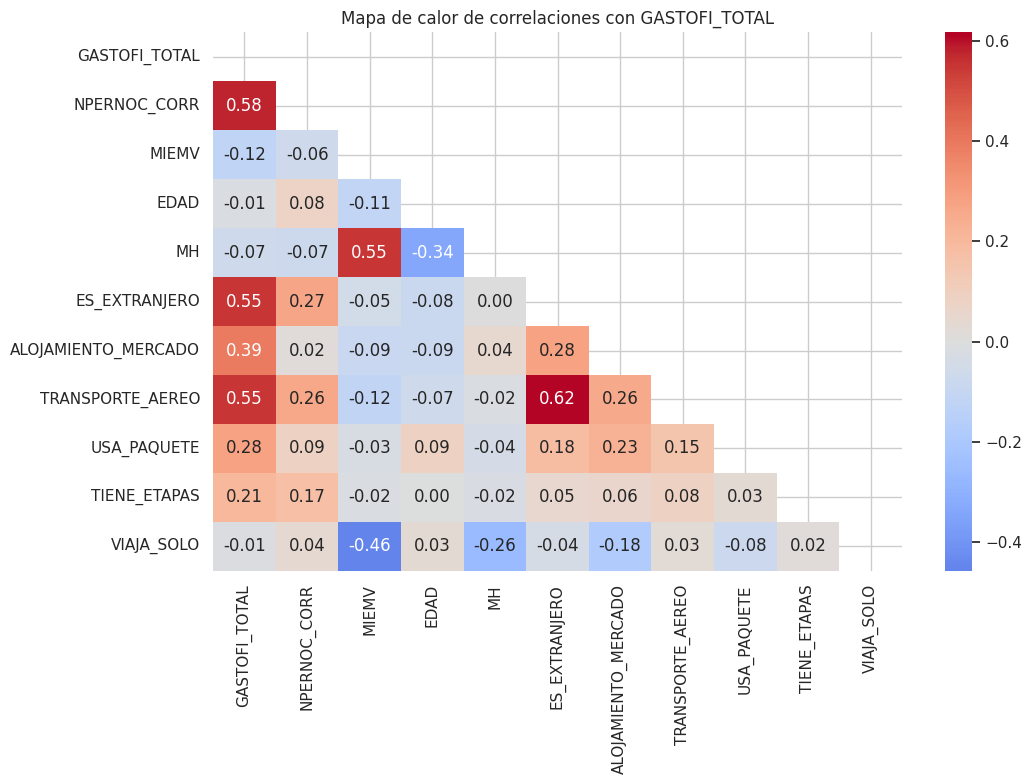

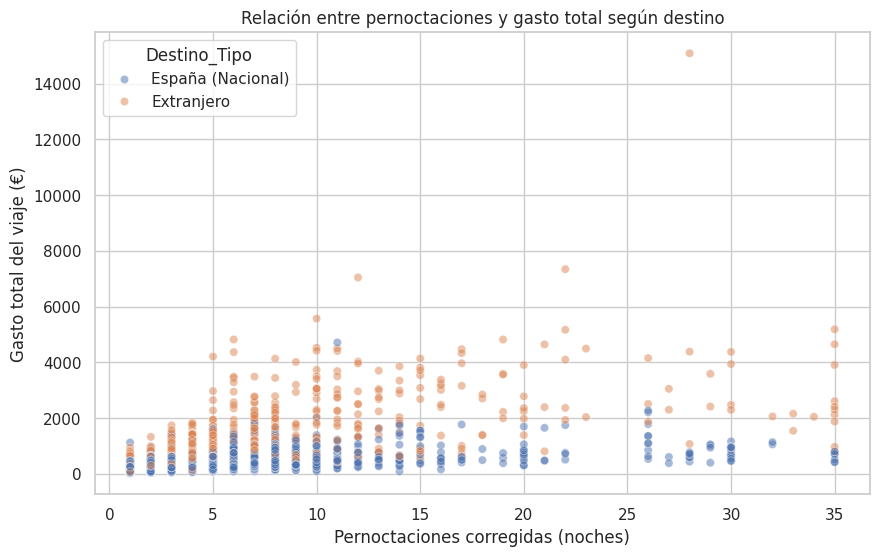

In [ ]:
# Calculamos correlaciones solo sobre variables numéricas e indicadores binarios (0/1)
df_corr = pd.DataFrame({
    "GASTOFI_TOTAL": df_eda["GASTOFI_TOTAL"],
    "NPERNOC_CORR": df_eda["NPERNOC_CORR"],
    "MIEMV": df_eda["MIEMV"],
    "EDAD": df_eda["EDAD"],
    "MH": df_eda["MH"],
    "ES_EXTRANJERO": (df_eda["DESTESP"] == 6).astype(int),
    "ALOJAMIENTO_MERCADO": (df_eda["ALOJAPRIN"] <= 9).astype(int),
    "TRANSPORTE_AEREO": (df_eda["TRANSPRIN"] == 1).astype(int),
    "USA_PAQUETE": (df_eda["PAQUETE"] == 1).astype(int),
    "TIENE_ETAPAS": (df_eda["BLOQUE_ETAPAS"] == 1).astype(int),
    "VIAJA_SOLO": df_eda["VIAJA_SOLO"].fillna(0).astype(int)
})

corr_matrix = df_corr.corr()
print("Correlación de cada variable con GASTOFI_TOTAL:")
print(corr_matrix["GASTOFI_TOTAL"].sort_values(ascending=False).round(3))

# Mapa de calor triangular inferior
plt.figure(figsize=(11, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Mapa de calor de correlaciones con GASTOFI_TOTAL")
plt.tight_layout()
plt.show()

# Gráfico de dispersión: Pernoctaciones vs Gasto Total según destino
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_eda[df_eda["NPERNOC_CORR"] <= 40],
    x="NPERNOC_CORR", y="GASTOFI_TOTAL",
    hue="Destino_Tipo", alpha=0.5
)
plt.title("Relación entre pernoctaciones y gasto total según destino")
plt.xlabel("Pernoctaciones corregidas (noches)")
plt.ylabel("Gasto total del viaje (€)")
plt.show()

### Conclusiones de la exploración gráfica

* El gasto mediano crece de forma clara cuando el viaje es al **extranjero**, cuando se utiliza **transporte aéreo** o cuando se contrata un **alojamiento de mercado** (hotel, apartamento turístico o crucero) frente a alojarse en vivienda propia o de familiares.
* Las correlaciones más altas con `GASTOFI_TOTAL` corresponden a la duración (`NPERNOC_CORR`, `r = 0,58`), viajar al extranjero (`ES_EXTRANJERO`, `r = 0,55`), desplazarse en avión (`TRANSPORTE_AEREO`, `r = 0,55`) y usar alojamiento de pago (`ALOJAMIENTO_MERCADO`, `r = 0,39`).
* En el gráfico de dispersión se aprecia además que, para un mismo número de noches, los viajes internacionales tienen una pendiente de gasto superior a los nacionales.

## 4. Exposición del objetivo

A partir del análisis anterior vemos que el desembolso económico de un viaje depende principalmente de su duración (`NPERNOC_CORR`), del destino (nacional o extranjero), del tipo de alojamiento y del medio de transporte.

* **Tipo de problema:** Aprendizaje **supervisado** de **regresión múltiple**.
* **Variable objetivo (*target*):** `GASTOFI_TOTAL` (importe total del gasto del viaje en euros).
* **Utilidad práctica:** Estimar el presupuesto esperado de un desplazamiento a partir de las características del viaje y el perfil del viajero.
* **Métricas de evaluación:**
  * **RMSE (*Root Mean Square Error*):** Mide la magnitud típica del error en **euros**, penalizando especialmente las desviaciones grandes:
    $$RMSE(X, h) = \sqrt{\frac{1}{m}\sum_{i=1}^{m}\left(h(x^{(i)}) - y^{(i)}\right)^2}$$
  * **MAE (*Mean Absolute Error*):** Mide el error medio absoluto en **euros** sin elevar al cuadrado las diferencias, lo que permite comprobar el error típico sin que los viajes más caros dominen la métrica:
    $$MAE(X, h) = \frac{1}{m}\sum_{i=1}^{m}\left|h(x^{(i)}) - y^{(i)}\right|$$
  * **Coeficiente de determinación ($R^2$):** Indica qué proporción de la variabilidad del gasto total es capaz de explicar el modelo.

## 5. Preparación de los datos para los algoritmos de Machine Learning

Preparamos los datos en seis pasos ordenados para evitar cualquier fuga de información y dejar el conjunto listo para entrenar:

1. **Eliminación de fuga de datos y variables redundantes:** Descartamos los desgloses e indicadores de gasto (`GASTOFI_*`, `GASTO_*`, `IGASTOFI_*`), los factores muestrales (`FACTORVI_*`, `FACTORGAS_TOT`, `CORR15_VT`), los identificadores (`IDSEC`, `ORDEN_VIAJE`), las valoraciones posteriores al viaje (`GRADO_SATISF`, `FIDELIDAD_DEST`) y `NPERNOC` (por estar ya depurada en `NPERNOC_CORR`).
2. **Filtrado de viajes únicos (`ORDEN_REP == 1`):** Conservamos únicamente la primera observación de cada viaje (`5.895` registros) y descartamos las `1.690` repeticiones de viajes recurrentes, ya que duplican exactamente las características y el gasto y provocarían fuga de datos entre entrenamiento y prueba.
3. **Tratamiento de valores nulos:** En las columnas `VIAJA_*` y `PAQUETE` (nulas solo en desplazamientos al trabajo) imputamos `0` y `6` ("No"), respectivamente; en `NIVELEST` y `RELAECON` (nulas solo en menores de 16 años) imputamos `1` (estudios primarios o inferiores) y `4` (resto inactivos).
4. **Ingeniería de características y limpieza de binarias:** Creamos atributos derivados claros (`ES_EXTRANJERO`, `ALOJAMIENTO_MERCADO`, `TRANSPORTE_AEREO`, `TIENE_ETAPAS`, `TIENE_VIVSEC` y `NOCHES_POR_MIEMBRO = NPERNOC_CORR / MIEMV`) y retiramos las columnas originales `DESTESP`, `BLOQUE_ETAPAS` y `VIVSEC` para no duplicar información.
5. **Codificación *One-Hot*:** Convertimos a variables binarias con `pd.get_dummies(..., dtype=int)` las columnas categóricas sin orden numérico continuo, incluyendo `INGR_HOG` (porque el código `9` significa "No contesta" y no un nivel de ingresos superior).
6. **Mezcla aleatoria y división Train / Test (80% / 20%):** Barajamos el dataset con `random_state=42` y separamos el 20% para la evaluación final independiente.

Nulos restantes tras la imputación: 0
Dimensiones X_train: (4716, 138)
Dimensiones X_test:  (1179, 138)


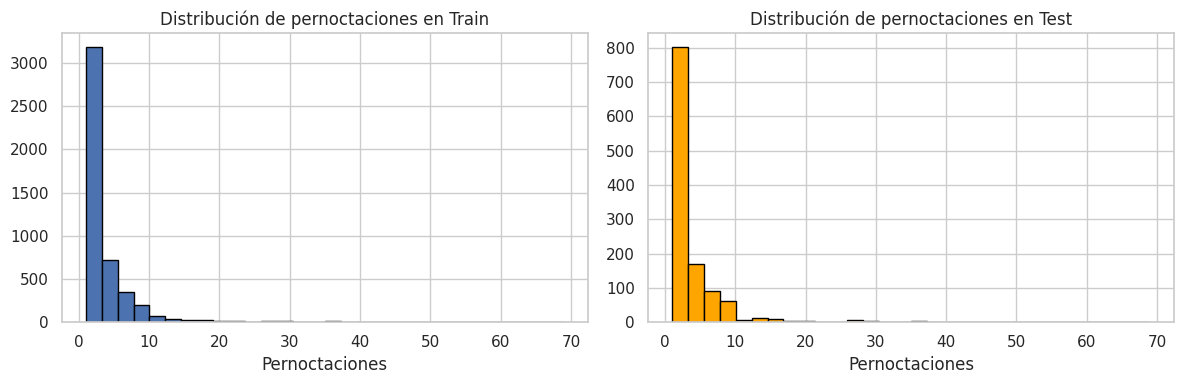

In [ ]:
from sklearn.model_selection import train_test_split

# 1. Filtrado de viajes únicos para evitar fuga por repeticiones recurrentes
viajes_unicos = viajes[viajes["ORDEN_REP"] == 1].copy()

# 2. Selección de características limpias (sin desgloses de gasto, factores ni variables post-viaje)
columnas_modelo = [
    "MES", "DESTESP", "PAISDEST", "CCAADEST", "MOTIV", "TIPOVIAJ",
    "NPERNOC_CORR", "ALOJAPRIN", "TRANSPRIN", "PAQUETE", "BLOQUE_ETAPAS",
    "VIAJA_SOLO", "VIAJA_PAREJA", "VIAJA_HIJOS", "VIAJA_OTROSFAMILIARES",
    "VIAJA_AMIGOS", "VIAJA_COMPTRABAJO", "MIEMV", "MIEMV_15MAS", "MIEMV_15MENOS",
    "SEXO", "EDAD", "CCAA_RESIDENCIA", "TAMAMU", "URBA",
    "NIVELEST", "RELAECON", "TIPHOGAR", "MH", "VIVSEC", "INGR_HOG",
    "GASTOFI_TOTAL"
]

df_ml = viajes_unicos[columnas_modelo].copy()

# 3. Imputación de valores nulos según el diseño del cuestionario
viaja_cols = [
    "VIAJA_SOLO", "VIAJA_PAREJA", "VIAJA_HIJOS",
    "VIAJA_OTROSFAMILIARES", "VIAJA_AMIGOS", "VIAJA_COMPTRABAJO"
]
df_ml[viaja_cols] = df_ml[viaja_cols].fillna(0)
df_ml["PAQUETE"] = df_ml["PAQUETE"].fillna(6)
df_ml["NIVELEST"] = df_ml["NIVELEST"].fillna(1)
df_ml["RELAECON"] = df_ml["RELAECON"].fillna(4)

print("Nulos restantes tras la imputación:", df_ml.isnull().sum().sum())

# 4. Ingeniería de características y paso a indicadores binarios limpios (0/1)
df_ml["ES_EXTRANJERO"] = (df_ml["DESTESP"] == 6).astype(int)
df_ml["ALOJAMIENTO_MERCADO"] = (df_ml["ALOJAPRIN"] <= 9).astype(int)
df_ml["TRANSPORTE_AEREO"] = (df_ml["TRANSPRIN"] == 1).astype(int)
df_ml["TIENE_ETAPAS"] = (df_ml["BLOQUE_ETAPAS"] == 1).astype(int)
df_ml["TIENE_VIVSEC"] = (df_ml["VIVSEC"] == 1).astype(int)
df_ml["NOCHES_POR_MIEMBRO"] = df_ml["NPERNOC_CORR"] / df_ml["MIEMV"]
df_ml = df_ml.drop(["DESTESP", "BLOQUE_ETAPAS", "VIVSEC"], axis=1)

# 5. Codificación One-Hot de variables categóricas (incluyendo INGR_HOG por el código 9 = No contesta)
cat_cols = [
    "PAISDEST", "CCAADEST", "MOTIV", "TIPOVIAJ", "ALOJAPRIN",
    "TRANSPRIN", "PAQUETE", "CCAA_RESIDENCIA", "NIVELEST",
    "RELAECON", "TIPHOGAR", "INGR_HOG"
]
df_encoded = pd.get_dummies(df_ml, columns=cat_cols, dtype=int)

# 6. Mezcla aleatoria y división Train (80%) / Test (20%)
df_encoded = df_encoded.sample(frac=1, random_state=42)

y = df_encoded["GASTOFI_TOTAL"]
X = df_encoded.drop("GASTOFI_TOTAL", axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"Dimensiones X_train: {X_train.shape}")
print(f"Dimensiones X_test:  {X_test.shape}")

# Comprobación visual de que Train y Test mantienen distribuciones similares
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
X_train["NPERNOC_CORR"].hist(bins=30, edgecolor="black", ax=axes[0])
axes[0].set_title("Distribución de pernoctaciones en Train")
axes[0].set_xlabel("Pernoctaciones")
X_test["NPERNOC_CORR"].hist(bins=30, edgecolor="black", ax=axes[1], color="orange")
axes[1].set_title("Distribución de pernoctaciones en Test")
axes[1].set_xlabel("Pernoctaciones")
plt.tight_layout()
plt.show()

## 6. Entrenamiento del modelo y comprobación del rendimiento

Comparamos cuatro modelos estándar de regresión mediante **validación cruzada con $K=5$ particiones** exclusivamente sobre el conjunto de entrenamiento (`X_train`, `y_train`):

1. **Regresión lineal regularizada (`StandardScaler` + `Ridge`):** Modelo lineal base con estandarización previa y regularización L2.
2. **Árbol de decisión (`DecisionTreeRegressor`):** Modelo no lineal capaz de capturar interacciones entre variables, aunque sensible al sobreajuste.
3. **Bosque aleatorio (`RandomForestRegressor`):** Conjunto de árboles que promedia sus predicciones para reducir la varianza.
4. **Gradient Boosting (`GradientBoostingRegressor`):** Ensamble secuencial de árboles que corrige de forma progresiva los errores residuales.

In [ ]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def evaluar_cv(modelo, nombre):
    puntuaciones = cross_validate(
        modelo, X_train, y_train, cv=5,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2"
        }
    )
    rmse = -puntuaciones["test_rmse"].mean()
    mae = -puntuaciones["test_mae"].mean()
    r2 = puntuaciones["test_r2"].mean()
    print(f"{nombre:28s} -> RMSE CV: {rmse:6.2f} € | MAE CV: {mae:6.2f} € | R² CV: {r2:.4f}")
    return {"Modelo": nombre, "RMSE CV (€)": rmse, "MAE CV (€)": mae, "R² CV": r2}

resultados_cv = []

# 1. Regresión lineal escalada (Ridge)
modelo_lineal = make_pipeline(StandardScaler(), Ridge(alpha=10.0))
modelo_lineal.fit(X_train, y_train)
resultados_cv.append(evaluar_cv(modelo_lineal, "Regresión lineal (Ridge)"))

# 2. Árbol de decisión
modelo_arbol = DecisionTreeRegressor(random_state=42)
modelo_arbol.fit(X_train, y_train)
resultados_cv.append(evaluar_cv(modelo_arbol, "Árbol de decisión"))

# 3. Random Forest
modelo_bosque = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)
modelo_bosque.fit(X_train, y_train)
resultados_cv.append(evaluar_cv(modelo_bosque, "Random Forest"))

# 4. Gradient Boosting
modelo_gb = GradientBoostingRegressor(random_state=42)
modelo_gb.fit(X_train, y_train)
resultados_cv.append(evaluar_cv(modelo_gb, "Gradient Boosting"))

pd.DataFrame(resultados_cv).round(3)

Regresión lineal (Ridge)     -> RMSE CV: 319.58 € | MAE CV: 148.44 € | R² CV: 0.7210
Árbol de decisión            -> RMSE CV: 346.33 € | MAE CV: 121.18 € | R² CV: 0.6435
Random Forest                -> RMSE CV: 259.22 € | MAE CV:  91.53 € | R² CV: 0.8146
Gradient Boosting            -> RMSE CV: 278.06 € | MAE CV:  93.66 € | R² CV: 0.7805


,Modelo,RMSE CV (€),MAE CV (€),R² CV
0,Regresión lineal (Ridge),319.578,148.443,0.721
1,Árbol de decisión,346.328,121.176,0.644
2,Random Forest,259.218,91.528,0.815
3,Gradient Boosting,278.058,93.664,0.780


### Ajuste de hiperparámetros con `GridSearchCV`

Como **Random Forest** obtiene los mejores resultados en validación cruzada, ajustamos sus hiperparámetros (`n_estimators`, `max_depth`, `min_samples_leaf` y `max_features`) sobre `X_train` mediante `GridSearchCV`, y lo comparamos en igualdad de condiciones ($K=5$) con los modelos anteriores antes de elegir el modelo final.

In [ ]:
from sklearn.model_selection import GridSearchCV

rejilla = {
    "n_estimators": [100, 150],
    "max_depth": [15, None],
    "min_samples_leaf": [1, 3],
    "max_features": [0.5, 1.0]
}

busqueda_grid = GridSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid=rejilla,
    cv=3,
    scoring="neg_root_mean_squared_error",
    n_jobs=1
)
busqueda_grid.fit(X_train, y_train)

print("Mejores hiperparámetros:", busqueda_grid.best_params_)

modelo_bosque_ajustado = RandomForestRegressor(
    **busqueda_grid.best_params_, random_state=42, n_jobs=-1
)
resultados_cv.append(evaluar_cv(modelo_bosque_ajustado, "Random Forest ajustado"))
modelo_bosque_ajustado.fit(X_train, y_train)

# Comparativa final mediante validación cruzada
tabla_resultados = pd.DataFrame(resultados_cv).sort_values("RMSE CV (€)").reset_index(drop=True)
display(tabla_resultados.round(3))

# Selección automática del mejor modelo según menor RMSE en validación cruzada
modelos = {
    "Regresión lineal (Ridge)": modelo_lineal,
    "Árbol de decisión": modelo_arbol,
    "Random Forest": modelo_bosque,
    "Gradient Boosting": modelo_gb,
    "Random Forest ajustado": modelo_bosque_ajustado
}
nombre_final = tabla_resultados.loc[0, "Modelo"]
modelo_final = modelos[nombre_final]
print(f"\nModelo seleccionado: {nombre_final}")

Mejores hiperparámetros: {'max_depth': None, 'max_features': 0.5, 'min_samples_leaf': 3, 'n_estimators': 100}
Random Forest ajustado       -> RMSE CV: 247.77 € | MAE CV:  89.58 € | R² CV: 0.8308


,Modelo,RMSE CV (€),MAE CV (€),R² CV
0,Random Forest ajustado,247.769,89.582,0.831
1,Random Forest,259.218,91.528,0.815
2,Gradient Boosting,278.058,93.664,0.780
3,Regresión lineal (Ridge),319.578,148.443,0.721
4,Árbol de decisión,346.328,121.176,0.644



Modelo seleccionado: Random Forest ajustado


### Evaluación final en el conjunto de prueba (`X_test`)

Evaluamos una única vez el modelo seleccionado sobre los datos reservados de prueba (`X_test`, `y_test`) y representamos el gasto real frente al gasto estimado.

RMSE en Test: 179.58 €
MAE en Test:  86.69 €
R² en Test:   0.9025


,Gasto real (€),Gasto estimado (€),Error absoluto (€)
0,628.50,602.91,25.59
1,304.18,346.34,42.16
2,405.06,499.06,94.00
3,64.60,122.91,58.31
4,189.90,280.51,90.61
5,186.79,186.33,0.46
6,216.28,296.43,80.15
7,385.28,308.22,77.06
8,267.68,272.58,4.90
9,620.74,580.78,39.96


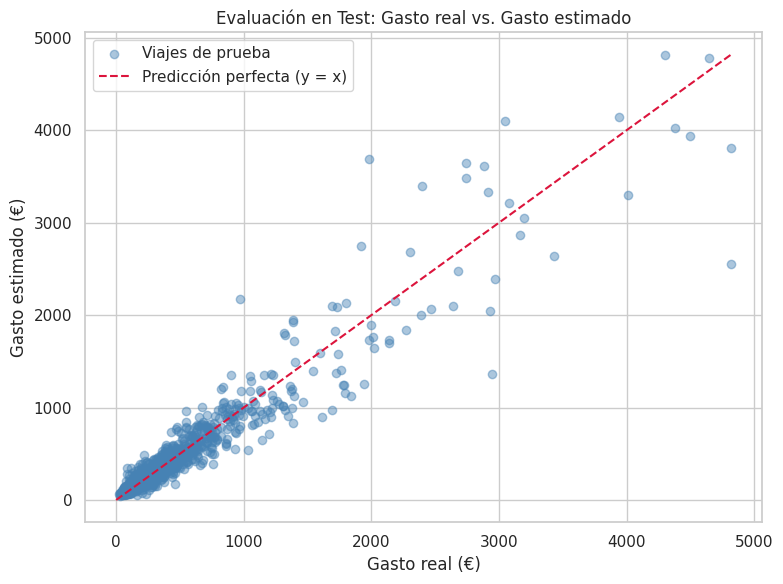

In [ ]:
y_pred_test = modelo_final.predict(X_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
mae_test = mean_absolute_error(y_test, y_pred_test)
r2_test = r2_score(y_test, y_pred_test)

print(f"RMSE en Test: {rmse_test:.2f} €")
print(f"MAE en Test:  {mae_test:.2f} €")
print(f"R² en Test:   {r2_test:.4f}")

# Tabla comparativa de las primeras 15 predicciones
comparativa_test = pd.DataFrame({
    "Gasto real (€)": y_test.values[:15],
    "Gasto estimado (€)": y_pred_test[:15],
    "Error absoluto (€)": np.abs(y_test.values[:15] - y_pred_test[:15])
})
display(comparativa_test.round(2))

# Gráfico de dispersión: gasto real vs. gasto estimado en Test
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred_test, alpha=0.45, color="steelblue", label="Viajes de prueba")
limite = max(y_test.max(), y_pred_test.max())
plt.plot([0, limite], [0, limite], color="crimson", linestyle="--", label="Predicción perfecta (y = x)")
plt.title("Evaluación en Test: Gasto real vs. Gasto estimado")
plt.xlabel("Gasto real (€)")
plt.ylabel("Gasto estimado (€)")
plt.legend()
plt.tight_layout()
plt.show()

### Importancia de las características

Inspeccionamos qué atributos tienen mayor peso en las decisiones del modelo seleccionado (teniendo en cuenta que la importancia es orientativa y no implica relación causal).

,Importancia
NPERNOC_CORR,0.1909
NOCHES_POR_MIEMBRO,0.1410
PAISDEST_108,0.1056
ES_EXTRANJERO,0.0674
ALOJAMIENTO_MERCADO,0.0674
CCAADEST_0,0.0538
PAISDEST_1,0.0444
TRANSPORTE_AEREO,0.0429
PAISDEST_4,0.0420
TRANSPRIN_1,0.0405


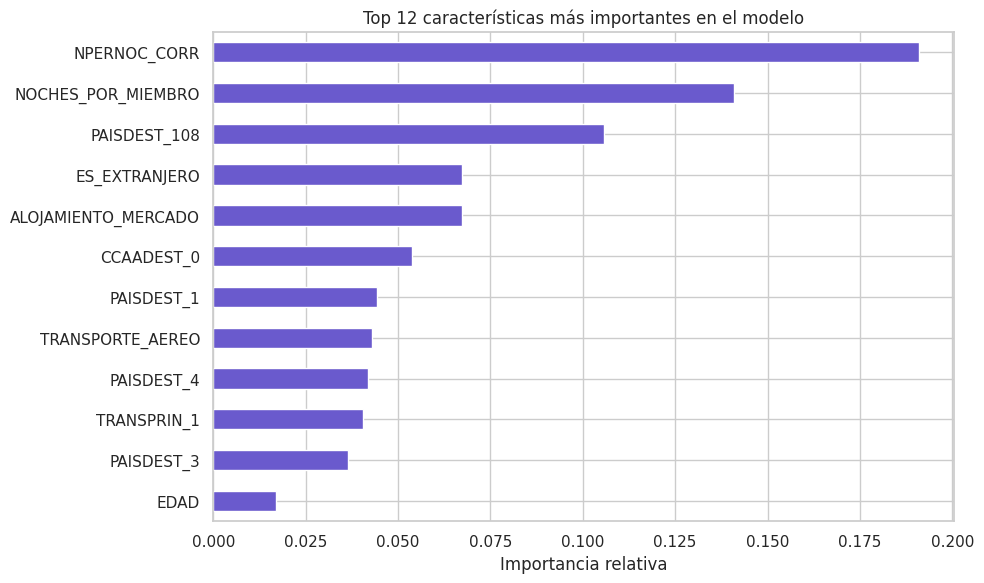

In [ ]:
if hasattr(modelo_final, "feature_importances_"):
    importancias = pd.Series(
        modelo_final.feature_importances_, index=X_train.columns
    ).sort_values(ascending=False)

    display(importancias.head(12).round(4).to_frame("Importancia"))
    importancias.head(12).sort_values().plot(kind="barh", color="slateblue")
    plt.title("Top 12 características más importantes en el modelo")
    plt.xlabel("Importancia relativa")
    plt.tight_layout()
    plt.show()

### Predicción sobre nuevos perfiles de viaje

Por último, definimos tres perfiles de viaje ficticios pero realistas con las variables originales del cuestionario y comprobamos qué gasto total estima el modelo para cada uno.

In [ ]:
datos_nuevos = pd.DataFrame([
    {
        # Perfil 1: Escapada nacional de fin de semana en coche a casa de familiares (2 noches)
        "MES": 11, "DESTESP": 1, "PAISDEST": 108, "CCAADEST": 1, "MOTIV": 8, "TIPOVIAJ": 2,
        "NPERNOC_CORR": 2, "ALOJAPRIN": 11, "TRANSPRIN": 5, "PAQUETE": 6, "BLOQUE_ETAPAS": 6,
        "VIAJA_SOLO": 0, "VIAJA_PAREJA": 1, "VIAJA_HIJOS": 0, "VIAJA_OTROSFAMILIARES": 0,
        "VIAJA_AMIGOS": 0, "VIAJA_COMPTRABAJO": 0, "MIEMV": 2, "MIEMV_15MAS": 2, "MIEMV_15MENOS": 0,
        "SEXO": 1, "EDAD": 35, "CCAA_RESIDENCIA": 13, "TAMAMU": 1, "URBA": 1,
        "NIVELEST": 4, "RELAECON": 1, "TIPHOGAR": 3, "MH": 2, "VIVSEC": 6, "INGR_HOG": 4
    },
    {
        # Perfil 2: Puente cultural de 4 noches en hotel en Madrid viajando en tren
        "MES": 12, "DESTESP": 1, "PAISDEST": 108, "CCAADEST": 13, "MOTIV": 2, "TIPOVIAJ": 1,
        "NPERNOC_CORR": 4, "ALOJAPRIN": 1, "TRANSPRIN": 10, "PAQUETE": 6, "BLOQUE_ETAPAS": 6,
        "VIAJA_SOLO": 0, "VIAJA_PAREJA": 1, "VIAJA_HIJOS": 0, "VIAJA_OTROSFAMILIARES": 0,
        "VIAJA_AMIGOS": 0, "VIAJA_COMPTRABAJO": 0, "MIEMV": 2, "MIEMV_15MAS": 2, "MIEMV_15MENOS": 0,
        "SEXO": 2, "EDAD": 42, "CCAA_RESIDENCIA": 1, "TAMAMU": 1, "URBA": 1,
        "NIVELEST": 4, "RELAECON": 1, "TIPHOGAR": 3, "MH": 2, "VIVSEC": 6, "INGR_HOG": 5
    },
    {
        # Perfil 3: Vacaciones de Navidad de 7 noches al extranjero (Europa) en avión y hotel
        "MES": 12, "DESTESP": 6, "PAISDEST": 1, "CCAADEST": 0, "MOTIV": 1, "TIPOVIAJ": 8,
        "NPERNOC_CORR": 7, "ALOJAPRIN": 1, "TRANSPRIN": 1, "PAQUETE": 1, "BLOQUE_ETAPAS": 6,
        "VIAJA_SOLO": 0, "VIAJA_PAREJA": 1, "VIAJA_HIJOS": 1, "VIAJA_OTROSFAMILIARES": 0,
        "VIAJA_AMIGOS": 0, "VIAJA_COMPTRABAJO": 0, "MIEMV": 3, "MIEMV_15MAS": 2, "MIEMV_15MENOS": 1,
        "SEXO": 1, "EDAD": 46, "CCAA_RESIDENCIA": 9, "TAMAMU": 1, "URBA": 1,
        "NIVELEST": 4, "RELAECON": 1, "TIPHOGAR": 4, "MH": 3, "VIVSEC": 1, "INGR_HOG": 6
    }
], index=["Viaje A (Familiar nacional)", "Viaje B (Hotel Madrid)", "Viaje C (Internacional avión)"])

# Aplicamos exactamente las mismas transformaciones que al entrenamiento
datos_nuevos["ES_EXTRANJERO"] = (datos_nuevos["DESTESP"] == 6).astype(int)
datos_nuevos["ALOJAMIENTO_MERCADO"] = (datos_nuevos["ALOJAPRIN"] <= 9).astype(int)
datos_nuevos["TRANSPORTE_AEREO"] = (datos_nuevos["TRANSPRIN"] == 1).astype(int)
datos_nuevos["TIENE_ETAPAS"] = (datos_nuevos["BLOQUE_ETAPAS"] == 1).astype(int)
datos_nuevos["TIENE_VIVSEC"] = (datos_nuevos["VIVSEC"] == 1).astype(int)
datos_nuevos["NOCHES_POR_MIEMBRO"] = datos_nuevos["NPERNOC_CORR"] / datos_nuevos["MIEMV"]
datos_nuevos = datos_nuevos.drop(["DESTESP", "BLOQUE_ETAPAS", "VIVSEC"], axis=1)

X_nuevos = pd.get_dummies(datos_nuevos, columns=cat_cols, dtype=int)
X_nuevos = X_nuevos.reindex(columns=X_train.columns, fill_value=0)

predicciones_nuevas = modelo_final.predict(X_nuevos)
display(pd.DataFrame({"Gasto total estimado (€)": predicciones_nuevas}, index=datos_nuevos.index).round(2))

,Gasto total estimado (€)
Viaje A (Familiar nacional),137.67
Viaje B (Hotel Madrid),665.20
Viaje C (Internacional avión),1339.84


## 7. Conclusiones

* **Comparación de algoritmos:** En validación cruzada sobre los `4.716` viajes únicos de entrenamiento, **Random Forest ajustado** logra el mejor rendimiento (`RMSE CV = 247,77 €`, `MAE CV = 89,58 €`, `R² CV = 0,8308`), superando a Random Forest por defecto, a Gradient Boosting, a la regresión lineal regularizada (`Ridge`) y al árbol de decisión individual (que sufre sobreajuste).
* **Rendimiento en evaluación independiente (`X_test`):** El modelo seleccionado obtiene un **`RMSE = 179,58 €`**, un **`MAE = 86,69 €`** y un **`R² = 0,9025`** sobre los `1.179` viajes de prueba. La diferencia entre el MAE y el RMSE refleja que la mayoría de predicciones tienen errores moderados, mientras que unos pocos viajes de coste muy elevado elevan el RMSE al penalizar los errores al cuadrado.
* **Factores principales del gasto:** Las variables con mayor peso en el modelo son la duración del viaje (`NPERNOC_CORR` y `NOCHES_POR_MIEMBRO`), si el destino es nacional o extranjero (`PAISDEST_108`, `ES_EXTRANJERO` y `CCAADEST_0`), contratar alojamiento de mercado (`ALOJAMIENTO_MERCADO`) y utilizar transporte aéreo (`TRANSPORTE_AEREO` y `TRANSPRIN_1`).
* **Limitaciones y mejoras futuras:**
  * Solo se han utilizado los microdatos de noviembre y diciembre de 2025, por lo que no se recoge la estacionalidad de verano o Semana Santa.
  * Al eliminar las `1.690` repeticiones (`ORDEN_REP > 1`) evitamos fuga de datos entre entrenamiento y prueba, aunque el modelo se entrena con viajes no repetidos.
  * Tampoco se han incluido atributos que solo existen para un subconjunto de viajes (como las estrellas del hotel `NESTR_PPAL` o el vuelo *low-cost* `LOW_COST`), ni variables de precios reales de billetes o tarifas hoteleras.
  * Como mejora futura, sería interesante ampliar el dataset a todo el año completo, probar una transformación logarítmica sobre `GASTOFI_TOTAL` para amortiguar la influencia de los viajes extremos e incorporar las variables condicionales de categoría hotelera y tipo de vuelo.